# Vẽ hồi quy Logistic cho ví dụ giờ ôn tập – kết quả thi (mục 4.1.4):

(a) xác suất thi đỗ theo số giờ, (b) hàm mất mát giảm dần qua các vòng lặp Gradient Descent

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Số giờ ôn tập và kết quả thi (1: đỗ, 0: trượt)

In [2]:
X = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
              2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50])
y = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])
Xbar = np.column_stack([np.ones(len(X)), X])   # vector mở rộng [1, x]

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def loss(w):
    """Hàm mất mát cross-entropy L(w)."""
    a = sigmoid(Xbar @ w)
    return -np.mean(y * np.log(a) + (1 - y) * np.log(1 - a))

Gradient Descent với tốc độ học η = 0.5, 2000 vòng lặp

In [3]:
w = np.zeros(2)
history = [loss(w)]                 # L(w) sau mỗi vòng lặp
for _ in range(2000):
    w = w - 0.5 * Xbar.T @ (sigmoid(Xbar @ w) - y) / len(y)
    history.append(loss(w))
print(w, history[-1])

[-4.07771247  1.5046451 ] 0.4014939232172412


Vẽ hình và lưu ảnh.

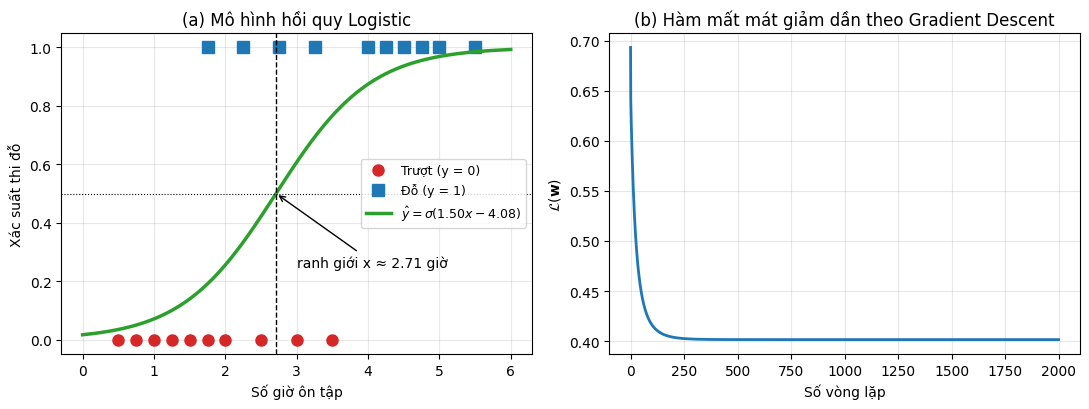

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
x_line = np.linspace(0, 6, 300)   # các điểm để vẽ đường cong
ax.plot(X[y == 0], y[y == 0], "o", color="#D62728", ms=8, label="Trượt (y = 0)")
ax.plot(X[y == 1], y[y == 1], "s", color="#1F77B4", ms=8, label="Đỗ (y = 1)")
ax.plot(x_line, sigmoid(w[0] + w[1] * x_line), color="#2CA02C", lw=2.5,
        label=rf"$\hat{{y}} = \sigma({w[1]:.2f}x {w[0]:+.2f})$")
boundary = -w[0] / w[1]             # ranh giới quyết định: w0 + w1 x = 0
ax.axhline(0.5, color="black", lw=0.8, ls=":")
ax.axvline(boundary, color="black", lw=1, ls="--")
ax.annotate(f"ranh giới x ≈ {boundary:.2f} giờ", (boundary, 0.5), (boundary + 0.3, 0.25),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Số giờ ôn tập"); ax.set_ylabel("Xác suất thi đỗ")
ax.set_title("(a) Mô hình hồi quy Logistic")
ax.legend(loc="center right", fontsize=9); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(history, color="#1F77B4", lw=2)
ax.set_xlabel("Số vòng lặp"); ax.set_ylabel(r"$\mathcal{L}(\mathbf{w})$")
ax.set_title("(b) Hàm mất mát giảm dần theo Gradient Descent")
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(IMAGES / "logistic_study_hours.png", dpi=150)